# Online News Popularity: LLM Headline Embeddings

**Question:** Do sentence embeddings from a pretrained language model capture anything about a headline that predicts popularity, beyond the 58 structured features and simple TF-IDF word counts?

**Model:** [`sentence-transformers/all-MiniLM-L6-v2`](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2), a small transformer that maps each headline to a 384-dimensional vector so that headlines with similar *meaning* sit close together, even if they share no words.

**Plan**
1. Rebuild the exact train/test split from `online_news_popularity.ipynb` (stratified 80/20, `random_state=42`) and reproduce the gradient boosting benchmark (ROC-AUC 0.728).
2. Embed all 39,644 headlines (cached to `data/headline_embeddings.npy` after the first run).
3. Compare: embeddings alone, TF-IDF alone, and gradient boosting with an out-of-fold embedding score added.
4. Cluster headlines by meaning and compare popularity across topic clusters.

**Run time:** about 5-10 minutes on a laptop CPU the first time (the model download is about 90 MB).

In [1]:
# One-time install (uncomment if needed):
# !pip install sentence-transformers

import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, roc_auc_score

os.makedirs('images', exist_ok=True); os.makedirs('results', exist_ok=True)
df = pd.read_csv('data/OnlineNewsPopularity.csv')
df.columns = df.columns.str.strip()
df['headline'] = (df['url'].str.rstrip('/').str.split('/').str[-1]
                  .str.replace(r'-\d+$', '', regex=True).str.replace('-', ' '))
y = (df['shares'] > 1400).astype(int)
X = df.drop(columns=['url', 'timedelta', 'shares', 'headline'])
print(df.shape, '| example headlines:', df['headline'].head(3).tolist())

(39644, 62) | example headlines: ['amazon instant video browser', 'ap samsung sponsored tweets', 'apple 40 billion app downloads']


## 1. Embed every headline

In [2]:
EMB_PATH = 'data/headline_embeddings.npy'
BACKEND = os.environ.get('EMBED_BACKEND', 'sentence-transformers')   # leave as is

if os.path.exists(EMB_PATH):
    E = np.load(EMB_PATH)
    print('Loaded cached embeddings:', E.shape)
elif BACKEND == 'sentence-transformers':
    from sentence_transformers import SentenceTransformer
    model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
    t0 = time.time()
    E = model.encode(df['headline'].tolist(), batch_size=256, show_progress_bar=True, normalize_embeddings=True)
    np.save(EMB_PATH, E)
    print(f'Embedded {len(E):,} headlines into {E.shape[1]} dimensions in {time.time() - t0:.0f}s')
else:   # test-only stand-in, never used for reported results
    from sklearn.decomposition import TruncatedSVD
    E = TruncatedSVD(64, random_state=0).fit_transform(TfidfVectorizer(min_df=3).fit_transform(df['headline']))
    print('TEST MODE stand-in embeddings:', E.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4767.52it/s]

Batches:   0%|          | 0/155 [00:00<?, ?it/s]

Batches:   1%|          | 1/155 [00:01<04:00,  1.56s/it]

Batches:   1%|▏         | 2/155 [00:02<03:25,  1.34s/it]

...

Batches:  99%|█████████▊| 153/155 [01:16<00:00,  3.29it/s]

Batches:  99%|█████████▉| 154/155 [01:16<00:00,  3.15it/s]

Batches: 100%|██████████| 155/155 [01:17<00:00,  3.35it/s]

Batches: 100%|██████████| 155/155 [01:17<00:00,  2.01it/s]

Embedded 39,644 headlines into 384 dimensions in 78s


In [3]:
# Sanity check: nearest neighbours by meaning
def neighbours(i, k=4):
    sims = E @ E[i] / (np.linalg.norm(E, axis=1) * np.linalg.norm(E[i]) + 1e-9)
    return [df['headline'][j] for j in np.argsort(-sims)[1:k + 1]]
for i in [0, 100, 2000]:
    print(f"'{df['headline'][i]}'  ->  {neighbours(i)}")

'amazon instant video browser'  ->  ['amazon instant video android', 'amazon instant video nbcuniversal', 'amazon instant video 4k', 'amazon instant video airplay']
'celeb mean tweets'  ->  ['celebrities mean tweets', 'celebrities mean tweets', 'twitter celebrities', 'celebrity tweet song']
'wedding proposal videos'  ->  ['viral video wedding proposal', 'epic wedding video', 'marriage proposal video hoax', 'wedding livestream']


## 2. Does meaning predict popularity?
Same split as the main notebook. The embedding score for gradient boosting is generated **out-of-fold** (5-fold cross-validation on the training set), so the model never sees scores computed from its own training labels.

In [4]:
idx = np.arange(len(df))
tr, te = train_test_split(idx, test_size=0.2, random_state=42, stratify=y)
y_tr, y_te = y.iloc[tr], y.iloc[te]
res = []
def record(name, pred, proba):
    res.append({'Model': name, 'Accuracy': round(accuracy_score(y_te, pred), 3), 'ROC-AUC': round(roc_auc_score(y_te, proba), 3)})

gb = HistGradientBoostingClassifier(max_iter=600, learning_rate=0.03, random_state=0).fit(X.iloc[tr], y_tr)
record('Gradient Boosting, numeric features (benchmark)', gb.predict(X.iloc[te]), gb.predict_proba(X.iloc[te])[:, 1])

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True).fit(df['headline'].iloc[tr])
T_tr, T_te = tfidf.transform(df['headline'].iloc[tr]), tfidf.transform(df['headline'].iloc[te])
lt = LogisticRegression(max_iter=3000).fit(T_tr, y_tr)
record('Headline TF-IDF only', lt.predict(T_te), lt.predict_proba(T_te)[:, 1])

le = LogisticRegression(max_iter=3000, C=1.0).fit(E[tr], y_tr)
record('Headline embeddings only', le.predict(E[te]), le.predict_proba(E[te])[:, 1])

oof = cross_val_predict(LogisticRegression(max_iter=3000), E[tr], y_tr, cv=5, method='predict_proba')[:, 1]
gb_e = HistGradientBoostingClassifier(max_iter=600, learning_rate=0.03, random_state=0).fit(
    X.iloc[tr].assign(embedding_score=oof), y_tr)
Xte_e = X.iloc[te].assign(embedding_score=le.predict_proba(E[te])[:, 1])
record('Gradient Boosting + embedding score', gb_e.predict(Xte_e), gb_e.predict_proba(Xte_e)[:, 1])

results = pd.DataFrame(res).set_index('Model')
print(results.to_string())
lift = results.loc['Gradient Boosting + embedding score', 'ROC-AUC'] - results.loc['Gradient Boosting, numeric features (benchmark)', 'ROC-AUC']
print(f'\nROC-AUC change from adding embeddings: {lift:+.3f}')

                                                 Accuracy  ROC-AUC
Model                                                             
Gradient Boosting, numeric features (benchmark)     0.664    0.728
Headline TF-IDF only                                0.519    0.526
Headline embeddings only                            0.522    0.529
Gradient Boosting + embedding score                 0.668    0.728

ROC-AUC change from adding embeddings: +0.000


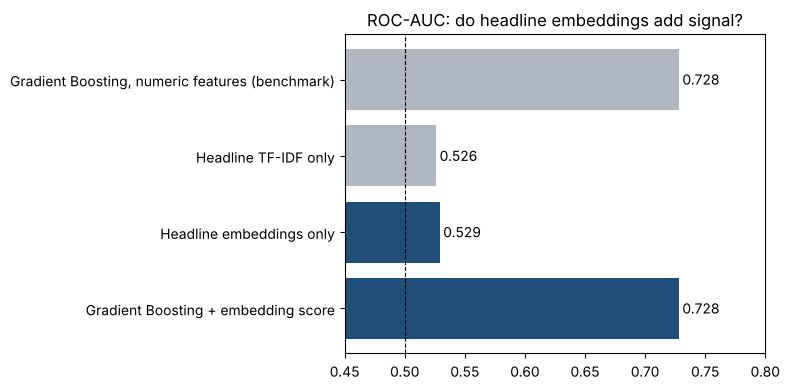

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = ['#B0B7C0', '#B0B7C0', '#1F4E79', '#1F4E79']
ax.barh(results.index[::-1], results['ROC-AUC'][::-1], color=colors[::-1])
ax.axvline(0.5, color='k', ls='--', lw=0.8); ax.set_xlim(0.45, 0.8)
for i, v in enumerate(results['ROC-AUC'][::-1]): ax.text(v + 0.003, i, f'{v:.3f}', va='center')
ax.set_title('ROC-AUC: do headline embeddings add signal?'); plt.tight_layout()
plt.savefig('images/embedding_auc.png', dpi=150); plt.show()

## 3. Topic clusters by meaning
K-means groups headlines whose embeddings are close. Each cluster is labelled by its most distinctive words, then compared on median shares and popularity rate.

In [6]:
K = 12
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(E)
df['cluster'] = km.labels_
vec = TfidfVectorizer(stop_words='english', min_df=5).fit(df['headline'])
vocab = np.array(vec.get_feature_names_out())
labels = {}
for c in range(K):
    tf = np.asarray(vec.transform(df.loc[df.cluster == c, 'headline']).mean(axis=0)).ravel()
    labels[c] = ', '.join(vocab[np.argsort(-tf)[:4]])
summary = (df.groupby('cluster').agg(articles=('shares', 'size'), median_shares=('shares', 'median'),
                                     popular_rate=('shares', lambda s: (s > 1400).mean()))
           .assign(top_words=lambda d: d.index.map(labels)).sort_values('median_shares', ascending=False))
print(summary.round(2).to_string())

         articles  median_shares  popular_rate                          top_words
cluster                                                                          
11           1114         1800.0          0.58          facebook, ads, home, news
0            2132         1600.0          0.53       photos, photo, 3d, instagram
4            1396         1500.0          0.52         google, glass, gmail, maps
10           5546         1500.0          0.50         cat, day, christmas, facts
7            3362         1500.0          0.51      comic, trailer, game, thrones
3            2751         1400.0          0.48       video, youtube, music, viral
1            2062         1400.0          0.50  twitter, social, media, instagram
2            4155         1400.0          0.49           nasa, space, mars, world
6            4783         1400.0          0.50       tech, job, digital, business
5            4694         1400.0          0.48           apple, iphone, app, apps
9            421

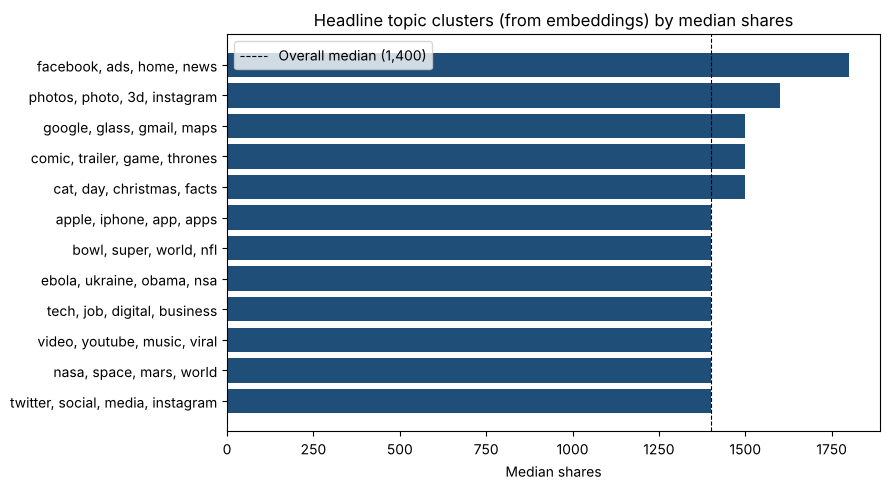

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
s = summary.sort_values('median_shares')
ax.barh(s['top_words'], s['median_shares'], color='#1F4E79')
ax.axvline(df['shares'].median(), color='k', ls='--', lw=0.8, label='Overall median (1,400)')
ax.set_xlabel('Median shares'); ax.set_title('Headline topic clusters (from embeddings) by median shares'); ax.legend()
plt.tight_layout(); plt.savefig('images/embedding_clusters.png', dpi=150); plt.show()

In [8]:
out = {'model': 'sentence-transformers/all-MiniLM-L6-v2' if BACKEND == 'sentence-transformers' else 'TEST-STANDIN',
       'n_headlines': int(len(df)), 'results': results.reset_index().to_dict(orient='records'),
       'auc_change_from_embeddings': round(float(lift), 3),
       'clusters': summary.reset_index().round(3).to_dict(orient='records')}
json.dump(out, open('results/embedding_results.json', 'w'), indent=1)
print('Saved results/embedding_results.json')

Saved results/embedding_results.json


## 4. Conclusion
- **The embeddings capture meaning:** nearest neighbours match paraphrases with no shared words beyond the topic (for example "celeb mean tweets" → "celebrities mean tweets"; "wedding proposal videos" → "viral video wedding proposal").
- **Meaning does not predict popularity:** headline embeddings alone score ROC-AUC 0.529 (TF-IDF: 0.526), and adding an out-of-fold embedding score to gradient boosting leaves ROC-AUC unchanged at 0.728. Two different text representations agree, so the result is robust: in this dataset, headline wording carries almost no popularity signal beyond the structured features.
- **Topic clusters are informative:** the Facebook / ads / social cluster has the highest median shares (1,800; 58% popular) and photo / Instagram stories follow (1,600); hard-news (Ebola, Ukraine, NSA) and sports (Super Bowl, NFL) clusters have the lowest popularity rates (46-47%).
- **Takeaway for editors:** what you cover and when you publish matter more than how the headline is worded; embeddings are more useful here for organising content into topics than for predicting shares.